#### SETUP ENVIRONMENT & GPU

In [ ]:
import os, sys
# This is a workaround for a bug in ipykernel that causes typing_extensions to be imported from the wrong location. 
sys.path = [p for p in sys.path if "ipykernel/py3" not in p] + [p for p in sys.path if "ipykernel/py3" in p]
for m in [m for m in sys.modules if m == "typing_extensions"]:
    del sys.modules[m]

import anndata
import numpy as np
import pandas as pd
import scanpy as sc
import scvi, torch

import seaborn as sns

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.neighbors import NearestNeighbors
from pathlib import Path

from flax.core.frozen_dict import FrozenDict
import hnoca.snapseed as snap
from hnoca.snapseed.utils import read_yaml

from scipy import stats

from scanpro import scanpro # For cell type proportion analysis

scvi.settings.device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {scvi.settings.device}")

#### Set paths

In [ ]:
QUERY_PATH = Path(
    "/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/"
    "01_qc_normalization/1.0_organoid_harmonized_DF.h5ad"
)

REF_PATH = "/dcs04/lieber/hwanglab/Arun/bmaher/Annotations/HNOCA_annotation/archmap/saved_scanvi_reference_model/data_with_count.h5ad"
REF_MODEL_DIR = "/dcs04/lieber/hwanglab/Arun/bmaher/Annotations/HNOCA_annotation/archmap/saved_scanvi_reference_model"

OUTPUT_DIR = "/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations"
os.makedirs(OUTPUT_DIR, exist_ok=True)

markerYAML ="/dcs04/lieber/hwanglab/Arun/bmaher/Annotations/HNOCA_annotation/Data_S1_snapseed_markers.yaml"

OUT_H5AD = OUTPUT_DIR + "/GRIA3_fai_HNOCA_annotated.h5ad"
UMAP_PDF = OUTPUT_DIR + "/GRIA3_fai_HNOCA_annotation_UMAPs.pdf"
N_NEIGHBORS = 50
QUERY_BATCH_SIZE = 2000
MAX_EPOCHS = 100

sc.settings.verbosity = 2
sc.settings.figdir    = OUTPUT_DIR
sc.set_figure_params(figsize=(6, 5), dpi=300, frameon=False)

#### 2. Load query and reference

In [46]:
print("Loading query...")
query_adata = sc.read_h5ad(QUERY_PATH)
print(query_adata)
print(f"Query cells: {query_adata.n_obs:,}")
print(f"Query genes: {query_adata.n_vars:,}")
print("Loading HNOCA reference...")
ref_adata = sc.read_h5ad(REF_PATH)
print(ref_adata)
print(f"Reference cells: {ref_adata.n_obs:,}")
print(f"Reference genes: {ref_adata.n_vars:,}")

marker_hierarchy = read_yaml(markerYAML)

Loading query...
AnnData object with n_obs × n_vars = 43598 × 38606
    obs: 'sample', 'cell_line', 'genome', 'genotype', 'pair', 'sample_batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'soupx_contamination', 'soupx_sample', 'doublet_method', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'cell_line_colors', 'genome_colors', 'genotype_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pair_colors', 'pca

#### 3. Generate Leiden clusters for query data

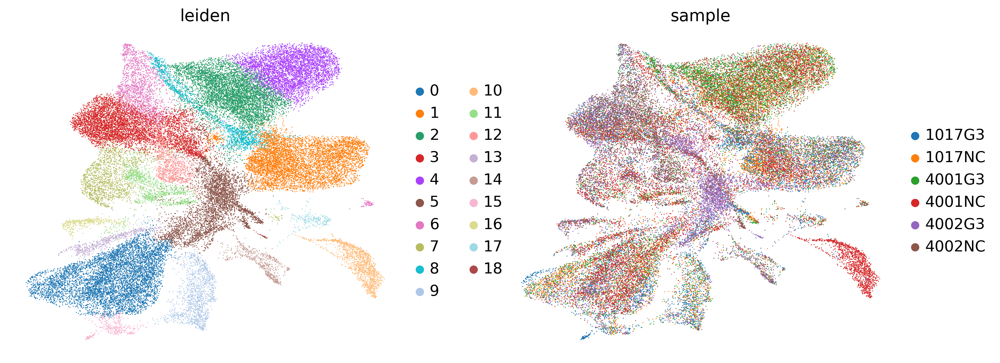

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
sc.pl.umap(
    query_adata,
    color= ["leiden", "sample"],
    # legend_loc="on data",
    # show=False,  # This prevents the plot from blocking execution
)

In [10]:
query_adata.obs 

,sample,cell_line,genome,genotype,pair,sample_batch,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,...,soupx_contamination,soupx_sample,doublet_method,doublet_score,predicted_doublet,S_score,G2M_score,phase,leiden,leiden_pca_rss_80
1017G3_AAACCCAAGACCCTTA-1,1017G3,1017G3,sow,KO,stem_1017DF,1017G3,884,6.785588,1460.0,7.286876,...,0.016,1017G3,Scrublet,0.025248,False,0.011252,-0.014884,S,5,20
1017G3_AAACCCAAGCGATTCT-1,1017G3,1017G3,sow,KO,stem_1017DF,1017G3,5796,8.665096,24642.0,10.112248,...,0.016,1017G3,Scrublet,0.030452,False,-0.009785,-0.091614,G1,1,6
1017G3_AAACCCACAAATGGAT-1,1017G3,1017G3,sow,KO,stem_1017DF,1017G3,7730,8.952993,36616.0,10.508268,...,0.016,1017G3,Scrublet,0.042882,False,0.029276,-0.102748,S,1,6
1017G3_AAACCCAGTCCCGGTA-1,1017G3,1017G3,sow,KO,stem_1017DF,1017G3,5568,8.624971,14900.0,9.609183,...,0.016,1017G3,Scrublet,0.030452,False,-0.022659,-0.115465,G1,0,12
1017G3_AAACCCAGTCTCACGG-1,1017G3,1017G3,sow,KO,stem_1017DF,1017G3,6191,8.731013,22759.0,10.032760,...,0.016,1017G3,Scrublet,0.034471,False,-0.037546,-0.132308,G1,7,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4002NC_TTTGGTTTCTATTGTC-1,4002NC,4002NC,slowbie,WT,stem_4002DF,4002NC,8823,9.085231,38706.0,10.563776,...,0.025,4002NC,Scrublet,0.066589,False,0.007413,-0.116192,S,12,7
4002NC_TTTGTTGCAGACGCTC-1,4002NC,4002NC,slowbie,WT,stem_4002DF,4002NC,6946,8.846065,28555.0,10.259623,...,0.025,4002NC,Scrublet,0.081846,False,-0.003483,-0.081565,G1,6,7
4002NC_TTTGTTGTCAAAGAAC-1,4002NC,4002NC,slowbie,WT,stem_4002DF,4002NC,1231,7.116394,2247.0,7.717796,...,0.025,4002NC,Scrublet,0.026847,False,-0.039361,-0.074294,G1,5,2
4002NC_TTTGTTGTCGGTGAAG-1,4002NC,4002NC,slowbie,WT,stem_4002DF,4002NC,7969,8.983440,36510.0,10.505369,...,0.025,4002NC,Scrublet,0.097889,False,-0.016602,-0.127667,G1,3,1


In [51]:
query_adata.obs.leiden.value_counts()

leiden
0     6230
1     6083
2     5630
3     5377
4     4330
5     4051
6     1706
7     1633
8     1442
9     1343
10    1315
11    1145
12    1076
13     597
14     550
15     407
16     407
17     245
18      31
Name: count, dtype: int64

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


#### 4. Marker Snapseed-based annotations

1017G3_AAACCCAAGACCCTTA-1     5
1017G3_AAACCCAAGCGATTCT-1     1
1017G3_AAACCCACAAATGGAT-1     1
1017G3_AAACCCAGTCCCGGTA-1     0
1017G3_AAACCCAGTCTCACGG-1     7
                             ..
4002NC_TTTGGTTTCTATTGTC-1    12
4002NC_TTTGTTGCAGACGCTC-1     6
4002NC_TTTGTTGTCAAAGAAC-1     5
4002NC_TTTGTTGTCGGTGAAG-1     3
4002NC_TTTGTTGTCTTTGCGC-1     5
Name: leiden, Length: 43598, dtype: str
Index(['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '2', '3', '4', '5', '6', '7', '8', '9'], dtype='str', name='leiden')
Leiden clusters without assignments:
{'18'}
                          leiden               snap_level_1         snap_level_2                     snap_level_3
1017G3_AAACCCAAGACCCTTA-1      5     neural_progenitor_cell  rhombencephalic_npc                              NaN
1017G3_AAACCCAAGCGATTCT-1      1     neural_progenitor_cell     diencephalic_npc                 hypothalamic_npc
1017G3_AAACCCACAAATGGAT-1      1     neural_progenitor_cell     diencephalic_npc        

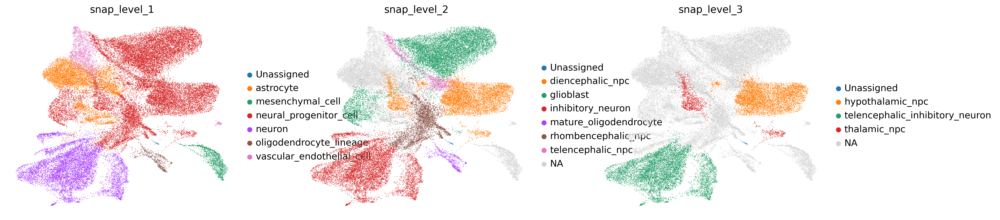

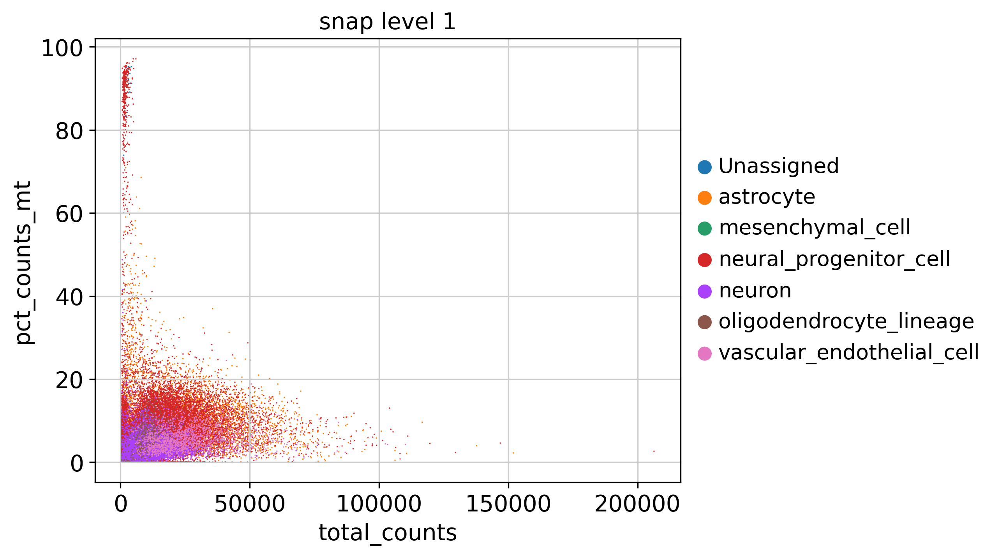

CellRank analysis complete.
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
assignments = snap.annotate_hierarchy(query_adata, marker_hierarchy, group_name="leiden") 

# Check which leiden clusters don't have assignments
leiden_values = query_adata.obs["leiden"].astype(str)
available_assignments = assignments["assignments"].index
print(leiden_values)
print(available_assignments)

print("Leiden clusters without assignments:")
print(set(leiden_values) - set(available_assignments))

# Filter to only valid leiden values
valid_mask = leiden_values.isin(available_assignments)

# Get assignments only for valid leiden clusters
cell_assign = assignments["assignments"].loc[leiden_values[valid_mask], :].copy()

# Merge back to original size, filling missing clusters with "Unassigned"
cell_assign_full = pd.DataFrame(
    index=query_adata.obs.index,
    columns=cell_assign.columns,
    data="Unassigned"
)
cell_assign_full.loc[valid_mask, :] = cell_assign.values

# Use the full assignment
query_adata.obs["snap_level_1"] = cell_assign_full["level_1"].values
query_adata.obs["snap_level_2"] = cell_assign_full["level_2"].values
query_adata.obs["snap_level_3"] = cell_assign_full["level_3"].values

print(query_adata.obs[["leiden", "snap_level_1", "snap_level_2", "snap_level_3"]])

axes = sc.pl.umap(
    query_adata,
    color=["snap_level_1", "snap_level_2", "snap_level_3"],
    show=False,  # This prevents the plot from blocking execution
)

# Access the underlying figure from the first axis and save it
axes[0].get_figure().savefig(UMAP_PDF, bbox_inches="tight")
plt.show()

ax = sc.pl.scatter(
    query_adata,
    x="total_counts",  # Replace with your actual variable
    y="pct_counts_mt",  # Replace with your actual variable
    color="snap_level_1",
    show=False,
)
SCATTER_PDF="/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/GRIA3_fai_HNOCA_annotation_scatter.pdf"
# Save the scatter plot figure cleanly
ax.get_figure().savefig(SCATTER_PDF, bbox_inches="tight")

# Display inline for your Jupyter Notebook / HTML export
plt.show()
print("CellRank analysis complete.")

#### 5. HNOCA annotations-based label transfer using scANVI

In [ ]:
# 1. Lean model-input object holding raw counts only
counts = query_adata.layers["counts"]
v = counts.data if hasattr(counts, "data") else np.asarray(counts).ravel()
assert np.isfinite(v).all() and (v >= 0).all() and np.allclose(v, np.round(v)), "not raw integer counts"

query_ref = anndata.AnnData(
    X=counts.copy(),
    obs=pd.DataFrame(index=query_adata.obs_names),
    var=pd.DataFrame(index=query_adata.var_names),
)
# query_ref.obs["batch"] = "query_" + query_adata.obs["cell_line"].astype(str)   # real per-cell values, prefixed to avoid clashing with reference batches
query_ref.obs["batch"] = query_adata.obs["sample"].astype(str)   # real per-cell values, prefixed to avoid clashing with reference batches
query_ref.obs["annot_level_1"] = "Unknown"

# 2. Subset and zero-pad to the reference genes, without touching query_adata
query_ref = scvi.model.SCANVI.prepare_query_anndata(query_ref, REF_MODEL_DIR, inplace=False)
if "counts" not in query_ref.layers:
    query_ref.layers["counts"] = query_ref.X.copy()          # covers a reference registered on layer="counts"

# 3. Surgery model, plus a check before training
query_scanvi_model = scvi.model.SCANVI.load_query_data(query_ref, REF_MODEL_DIR)

# 4. Train
print("CUDA available:", torch.cuda.is_available())
query_scanvi_model.train(max_epochs=MAX_EPOCHS, plan_kwargs={"weight_decay": 0.0}, early_stopping=True)

# 5. Predict once, write results back to the full object
soft = query_scanvi_model.predict(query_ref, soft=True)
query_adata.obs["predicted_label"] = soft.idxmax(axis=1).reindex(query_adata.obs_names).astype("category")
query_adata.obs["prediction_confidence"] = soft.max(axis=1).reindex(query_adata.obs_names)
z = pd.DataFrame(query_scanvi_model.get_latent_representation(query_ref), index=query_ref.obs_names)
query_adata.obsm["X_scANVI"] = z.reindex(query_adata.obs_names).to_numpy()

# Now you can check for NaNs after training
assert np.isfinite(z.values).all(), "NaN latent after training"

print(query_adata.obs["predicted_label"].value_counts())

#### 6. Transfer the other annotation labels based on Nearest Neighbors

In [ ]:
transfer_labels = ["annot_level_1", "annot_level_2", "annot_region_rev2", "annot_level_3_rev2", "annot_ntt_rev2", "annot_level_4_rev2"]

for label in transfer_labels:
    if label not in ref_adata.obs:
        raise KeyError(f"{label} not found in reference AnnData.")

# Use it
z_query = query_scanvi_model.get_latent_representation(query_ref)
z_ref = query_scanvi_model.get_latent_representation(ref_adata)

print("\nTransferring HNOCA annotations...")
knn = NearestNeighbors(
    n_neighbors=N_NEIGHBORS,
    metric="euclidean",
    algorithm="auto",
    n_jobs=-1
)
knn.fit(z_ref)

print("Finding reference neighbors...")
all_indices = []
for start in range(0, z_query.shape[0], QUERY_BATCH_SIZE):
    end = min(start + QUERY_BATCH_SIZE, z_query.shape[0])
    print(f"  Query cells {start:,} - {end:,}")
    _, idx = knn.kneighbors(z_query[start:end])
    all_indices.append(idx)
neighbor_indices = np.vstack(all_indices)

for label in transfer_labels:
    print(f"  {label}")
    ref_labels = ref_adata.obs[label].astype(str).to_numpy()
    transferred = []
    for idx in neighbor_indices:
        labels = ref_labels[idx]
        transferred.append(pd.Series(labels).value_counts().index[0])
    query_adata.obs[label] = pd.Categorical(transferred)

print(f"✓ Transferred {len(transfer_labels)} labels")

In [ ]:
query_adata.var.shape

In [ ]:
for label in transfer_labels:
    print(f"\n{label}:")
    print(query_adata.obs[label].value_counts())

#### 7. Compute SCANVI UMAP

In [66]:
print("\nComputing SCANVI UMAP...")
sc.pp.neighbors(query_adata, use_rep="X_scANVI", n_neighbors=15)
sc.tl.umap(query_adata, min_dist=0.3)


Computing SCANVI UMAP...
computing neighbors
    finished (0:00:04)
computing UMAP
    finished (0:00:35)
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
query_adata.raw.X

In [ ]:
import numpy as np, scipy.sparse as sp

rng = np.random.default_rng(0)
idx = np.sort(rng.choice(query_adata.n_obs, 2000, replace=False))
dense = lambda M: M.toarray() if sp.issparse(M) else np.asarray(M)

print("X:", query_adata.shape, "| raw:", query_adata.raw.shape, "| layers:", list(query_adata.layers))
print("raw genes cover X genes:", query_adata.var_names.isin(query_adata.raw.var_names).all())

X = dense(query_adata.X[idx])
print("\nX      sparse:", sp.issparse(query_adata.X), "| min/max:", X.min().round(2), X.max().round(2),
      "| frac == 10:", (X == 10).mean().round(4),
      "| median gene mean/std:", np.median(X.mean(0)).round(3), np.median(X.std(0)).round(3))

C = dense(query_adata.layers["counts"][idx])
print("counts integer:", np.allclose(C, np.round(C)), "| min/max:", C.min(), C.max())

R = dense(query_adata.raw.X[idx])
print("raw.X  min/max:", R.min().round(2), R.max().round(2),
      "| median expm1 row sum:", np.median(np.expm1(R).sum(1)).round(1))

In [ ]:
# Save the log-normalized expression values in a new layer for downstream analysis
query_adata.layers["lognorm"] = query_adata.raw[:, query_adata.var_names].X.copy()

## Matrix	 | Result	 |  Verdict
# .X	| dense, min -7.86, max 10.0, 0.11% of values at exactly 10, median gene mean -0.01 and std 0.89  |  z-scored and clipped at 10
# .layers["counts"]	| integers, 0 to 3017  |  raw counts
# .raw.X	| min 0, max 8.04, median expm1 row sum 10000  |  log-normalized (normalize_total to 1e4, then log1p)

#### 8. Save the annotated query AnnData to disk

In [ ]:
query_adata.write_h5ad(OUT_H5AD)
print(f"\nSaved annotated query AnnData to {OUT_H5AD}")

In [ ]:
query_adata.obs.head()

,sample,cell_line,genome,genotype,pair,sample_batch,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,...,_scvi_labels,batch,annot_level_1,predicted_label,prediction_confidence,annot_level_2,annot_region_rev2,annot_level_3_rev2,annot_ntt_rev2,annot_level_4_rev2
1017G3_AAACCCAAGACCCTTA-1,1017G3,1017G3,sow,KO,stem_1017DF,1017G3,884,6.785588,1460.0,7.286876,...,13,cell_line,Neuron,Neuron,0.998048,Non-telencephalic Neuron,Medulla,Medulla Neuron,NT-VGLUT,Thalamic Neuron NT-VGLUT
1017G3_AAACCCAAGCGATTCT-1,1017G3,1017G3,sow,KO,stem_1017DF,1017G3,5796,8.665096,24642.0,10.112248,...,13,cell_line,MC,MC,0.761395,MC,Unspecific,MC,,MC
1017G3_AAACCCACAAATGGAT-1,1017G3,1017G3,sow,KO,stem_1017DF,1017G3,7730,8.952993,36616.0,10.508268,...,13,cell_line,MC,MC,0.697660,MC,Unspecific,MC,,MC
1017G3_AAACCCAGTCCCGGTA-1,1017G3,1017G3,sow,KO,stem_1017DF,1017G3,5568,8.624971,14900.0,9.609183,...,13,cell_line,Neuron,Neuron,1.000000,Ventral Telencephalic Neuron,Ventral telencephalon,Ventral Telencephalic Neuron,NT-GABA,Ventral Telencephalic Neuron NT-GABA
1017G3_AAACCCAGTCTCACGG-1,1017G3,1017G3,sow,KO,stem_1017DF,1017G3,6191,8.731013,22759.0,10.032760,...,13,cell_line,Astrocyte,Astrocyte,1.000000,Astrocyte,Unspecific,Astrocyte,,Astrocyte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4002NC_TTTGGTTTCTATTGTC-1,4002NC,4002NC,slowbie,WT,stem_4002DF,4002NC,8823,9.085231,38706.0,10.563776,...,13,cell_line,NPC,NPC,0.621546,Non-telencephalic NPC,Unspecific,Medulla NPC,,Medulla NPC
4002NC_TTTGTTGCAGACGCTC-1,4002NC,4002NC,slowbie,WT,stem_4002DF,4002NC,6946,8.846065,28555.0,10.259623,...,13,cell_line,Glioblast,Glioblast,0.728473,Glioblast,Unspecific,Glioblast,,Glioblast
4002NC_TTTGTTGTCAAAGAAC-1,4002NC,4002NC,slowbie,WT,stem_4002DF,4002NC,1231,7.116394,2247.0,7.717796,...,13,cell_line,Astrocyte,Astrocyte,0.998557,Astrocyte,Unspecific,Astrocyte,,Astrocyte
4002NC_TTTGTTGTCGGTGAAG-1,4002NC,4002NC,slowbie,WT,stem_4002DF,4002NC,7969,8.983440,36510.0,10.505369,...,13,cell_line,Astrocyte,Astrocyte,0.999889,Astrocyte,Unspecific,Astrocyte,,Astrocyte


ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


#### 9. UMAP's and celltype proportions

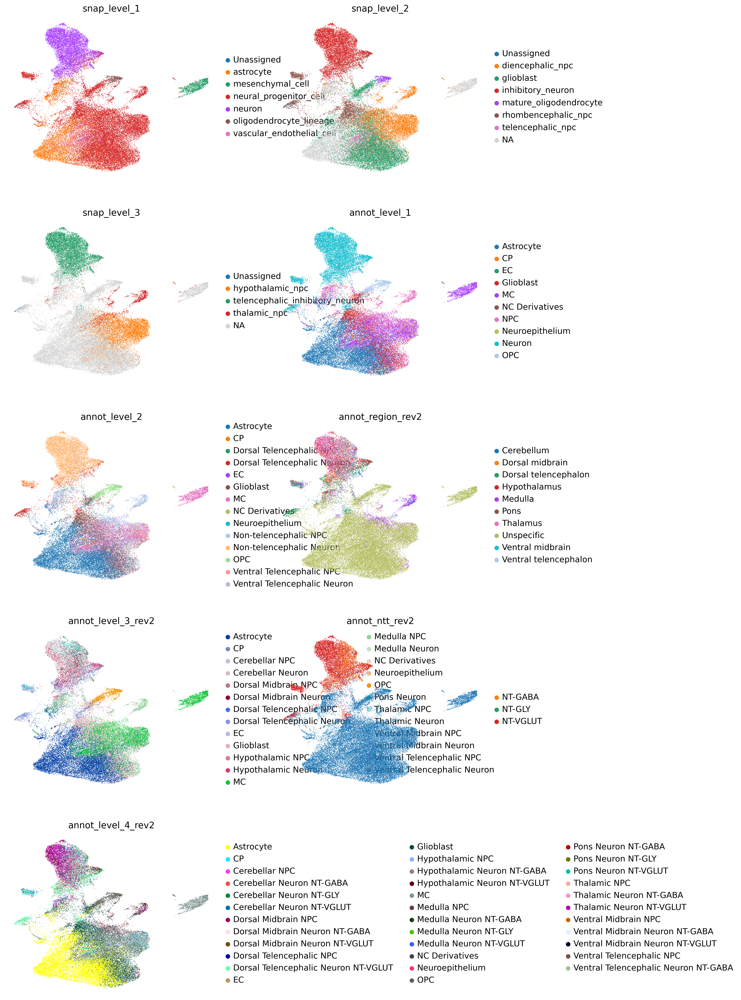

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [68]:
new_transfer_labels = ["snap_level_1", "snap_level_2", "snap_level_3"] + transfer_labels
# sc.pl.umap(query_adata, color=new_transfer_labels, ncols=2)

axes = sc.pl.umap(
    query_adata,
    color=new_transfer_labels, ncols=2,
    show=False,  # This prevents the plot from blocking execution
)
UMAP_PDF="/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/GRIA3_fai_advanced_HNOCA_annotation_UMAPs.pdf"
# Access the underlying figure from the first axis and save it
axes[0].get_figure().savefig(UMAP_PDF, bbox_inches="tight")
plt.show()


In [ ]:
UMAP_PDF="/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/GRIA3_fai_advanced_HNOCA_annotation_UMAPs_v2.pdf"
plot_labels = [
    "annot_level_1",
    "snap_level_1",
    "snap_level_2",
    "snap_level_3",
    
    "annot_level_2",
    "annot_level_3_rev2",
    
    # "annot_ntt_rev2",
    # "annot_level_4_rev2",
    # "annot_region_rev2",
]
plot_titles = [
    "HNOCA annot_level_1",
    "Snapseed level 1",
    "Snapseed level 2",
    "Snapseed level 3",

    "HNOCA annot_level_2",
    "HNOCA annot_level_3_rev2",

    # "HNOCA annot_ntt_rev2",
    # "HNOCA annot_level_4_rev2",
    # "HNOCA annot_region_rev2",
]
print("\nCreating UMAP PDF...")
with PdfPages(UMAP_PDF) as pdf:
    fig, axes = plt.subplots(3, 2, figsize=(18, 28))
    axes = axes.flatten()
    for ax, label, title in zip(axes, plot_labels, plot_titles):
        if label in query_adata.obs:
            sc.pl.umap(query_adata, color=label, ax=ax, show=False, frameon=False, title=title, legend_loc="right margin")
        else:
            ax.axis("off")
            ax.set_title(f"{title} not available")
    plt.tight_layout()
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

# ============================================================
# 18. Save annotated query
# ============================================================
print("\nSaving annotated query...")
# query_adata.write_h5ad(OUT_H5AD)
print("\nDONE")
print("Annotated query:", OUT_H5AD)
print("UMAP PDF:", UMAP_PDF)


Creating UMAP PDF...

Saving annotated query...

DONE
Annotated query: /dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/GRIA3_fai_HNOCA_annotated.h5ad
UMAP PDF: /dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/GRIA3_fai_advanced_HNOCA_annotation_UMAPs_v2.pdf
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
query_adata.obs.groupby("sample")["total_counts"].sum()
sample_summary = query_adata.obs.groupby("sample")["total_counts"].agg(
    cell_count="count", total_sum="sum"
)
print(sample_summary)

print(query_adata.layers['counts'].shape)

In [ ]:
marker_plot = "/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/GRIA3_fai_markerGenes.pdf"
# Assuming your AnnData object is named 'query_adata'
# Ensure you are using log-normalized counts for visualization
marker_genes = {
    'Pan-Oligo Lineage': ['OLIG1', 'OLIG2', 'SOX10'],
    'OPC': ['PDGFRA', 'CSPG4'],
    'Immature Oligo': ['NKX2-2', 'BCAS1'],
    'Mature/Myelinating': ['MBP', 'PLP1', 'MAG', 'MOG', 'CNP'],
    # 'Pasca_genes': ['TOP2A','MKI67', 'ASPM', 'PTPRZ1', 'PDGFRA', 'PCDH15', 'NXPH1', 'SERPINC5', 'PMP22', 'KLK6', 'APOD', 'GAPDH']
}

# 1. Flatten the dictionary to get a unique list of genes present in your data
all_markers = [gene for sublist in marker_genes.values() for gene in sublist]
valid_markers = [gene for gene in all_markers if gene in query_adata.var_names]

print(f"Found {len(valid_markers)} out of {len(all_markers)} marker genes in dataset.")

# 2. Plot a Matrixplot grouped by your existing automated annotations
# This reveals if 'neurons' or 'astrocytes' are actually expressing oligo markers
sc.pl.matrixplot(
    query_adata, 
    var_names=valid_markers, 
    groupby='annot_level_1',  
    use_raw=False,
    swap_axes=True,
    # figsize=(12, 14),
    figsize=(8, 6),
    # show=False, 
    save="GRIA3_fai_markerGenes_matrixplot_v2.pdf"
    )

# 3. Calculate Fraction of Cells Expressing Markers Above Background
# Determine how many total cells show authentic lineage signal
expression_threshold = 0.5  # Adjust based on your log1p normalized data layout
expressed_df = query_adata[:, valid_markers].to_df()
pct_expressed = (expressed_df > expression_threshold).mean() * 100

print("\nPercentage of total cells expressing each marker:")
print(pct_expressed.round(2))

In [ ]:

# Define a strict pan-lineage gene list present in your plot
oligo_lineage_genes = ['OLIG1', 'OLIG2', 'SOX10', 'PDGFRA', 'BCAS1', 'PLP1']

# Calculate a module score per cell relative to control background genes
sc.tl.score_genes(
    query_adata, 
    gene_list=oligo_lineage_genes, 
    score_name='Oligo_Lineage_Score',
    layer='lognorm'  # Use the normalized counts layer for scoring
)

# Check the average lineage score across your current labels
scores_by_celltype = query_adata.obs.groupby('annot_level_1')['Oligo_Lineage_Score'].mean()
print("Average Oligodendrocyte Lineage Score by cell type:")
print(scores_by_celltype.sort_values(ascending=False))

# Quantify what % of your dataset is genuinely part of this lineage
# (Cells with a score > 0 are enriched relative to background)
true_oligo_cells = query_adata.obs['Oligo_Lineage_Score'] > 0.1  # Adjust threshold if needed
pct_enriched = true_oligo_cells.mean() * 100

print(f"\n{pct_enriched:.2f}% of the total cells are enriched for the oligodendrocyte lineage.")

computing score 'Oligo_Lineage_Score'
    finished (0:00:00)
Average Oligodendrocyte Lineage Score by cell type:
annot_level_1
OPC                2.503219
NC Derivatives     0.871293
EC                 0.642616
Neuroepithelium    0.010060
Astrocyte          0.001944
Glioblast         -0.015553
MC                -0.058668
NPC               -0.126057
Neuron            -0.132326
CP                -0.173674
Name: Oligo_Lineage_Score, dtype: float64

20.13% of the total cells are enriched for the oligodendrocyte lineage.
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# OL_UMAP_PDF = "/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/final_lineage_annotation_UMAP.pdf"
# # 1. Establish the clean biological classification mapping
# query_adata.obs['final_lineage_annotation'] = query_adata.obs['annot_level_1'].astype(str)

# # Use your functional 0.4 score cutoff to capture the transitional continuum
# is_oligo_lineage = query_adata.obs['Oligo_Lineage_Score'] > 0.4
# query_adata.obs.loc[is_oligo_lineage, 'final_lineage_annotation'] = 'Oligodendrocyte Lineage'

# # 2. Render and save the static cluster UMAP
# sc.settings.set_figure_params(figsize=(6, 5), dpi=300, frameon=False)
# ax = sc.pl.umap(query_adata, color='final_lineage_annotation', show=False)
# ax.set_title("Organoid Profiles with Restored Oligodendrocyte Lineage")
# ax.figure.savefig(OL_UMAP_PDF, bbox_inches='tight')

computing neighbors
    finished (0:00:04)
running PAGA
    finished (0:00:00)


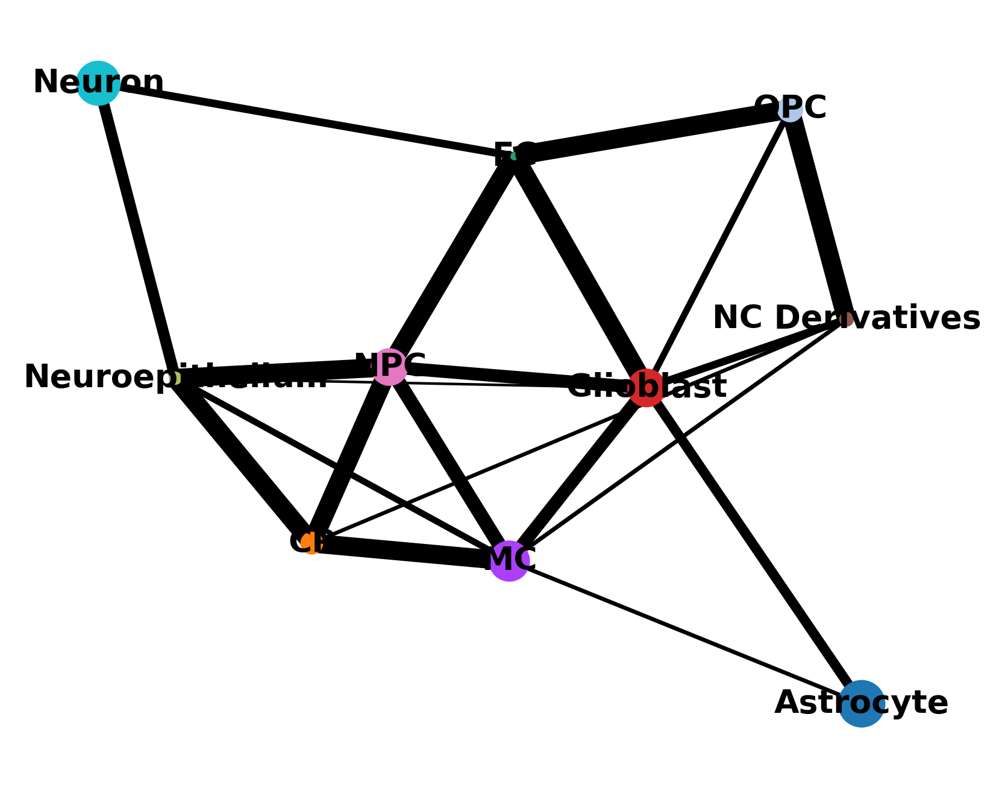

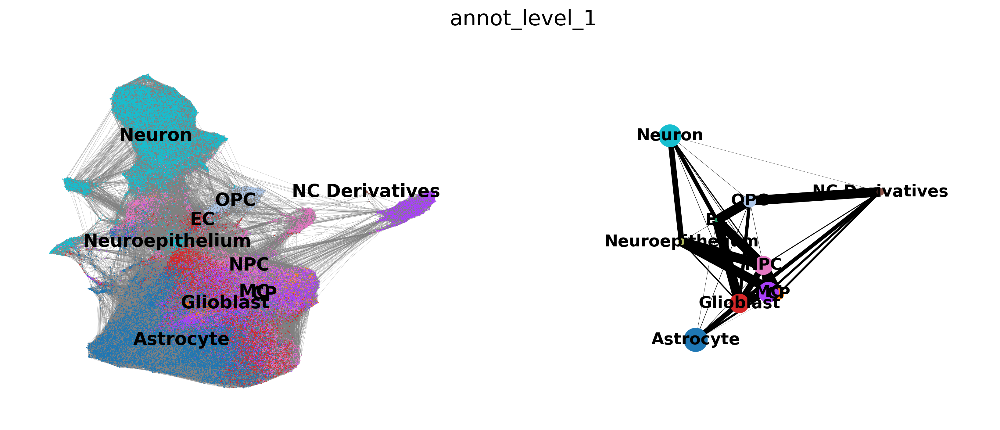

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# # 1. Generate neighborhood graph topology if not already calculated
# sc.pp.neighbors(query_adata, use_rep='X_scANVI') # or your harmonized embedding key

# # 2. Compute PAGA connectivity matrix over your original labels
# sc.tl.paga(query_adata, groups='annot_level_1')

# # 3. Plot the structural connection tree map
# sc.pl.paga(
#     query_adata, 
#     color='annot_level_1', 
#     threshold=0.12, 
#     show=False
# )
# plt.savefig("/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/paga_structural_connectivity.pdf", bbox_inches='tight')

# # 4. Project the trajectory lines directly onto your cell cloud UMAP
# sc.pl.paga_compare(
#     query_adata,
#     basis='umap',
#     color='annot_level_1',
#     edges=True,
#     show=False
# )
# plt.savefig("/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/oligo_developmental_trajectory_umap.pdf", bbox_inches='tight')

computing Diffusion Pseudotime using n_dcs=10
    finished (0:00:00)


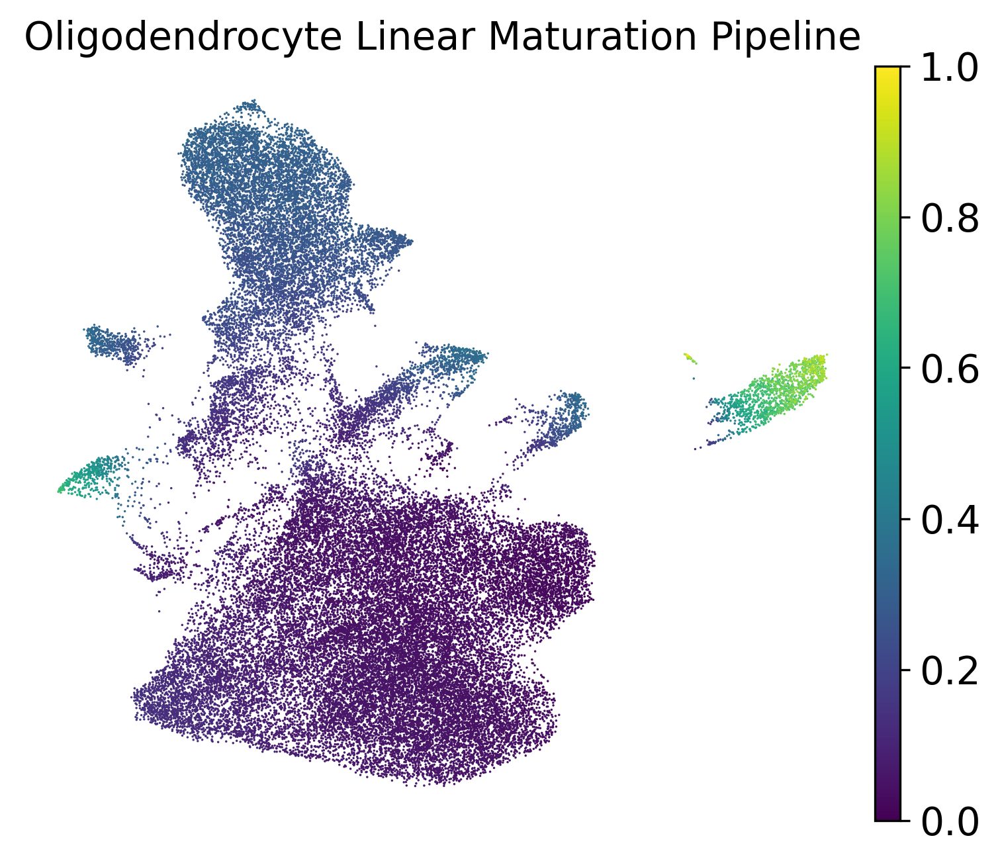

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# # 1. Define a root anchor cell within your early precursor cluster
# root_cells = np.where(query_adata.obs['annot_level_1'] == 'NC Derivatives')[0]
# if len(root_cells) > 0:
#     query_adata.uns['iroot'] = root_cells[0]
# else:
#     raise ValueError("Target cluster 'NC Derivatives' not found in annot_level_1 metadata.")

# # 2. Map continuous trajectory values away from the root anchor
# sc.tl.dpt(query_adata)

# # 3. Display the linear maturation gradient across your dataset
# ax_time = sc.pl.umap(query_adata, color='dpt_pseudotime', cmap='viridis', show=False)
# ax_time.set_title("Oligodendrocyte Linear Maturation Pipeline")
# ax_time.figure.savefig("/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/oligo_pseudotime_trajectory.pdf", bbox_inches='tight')


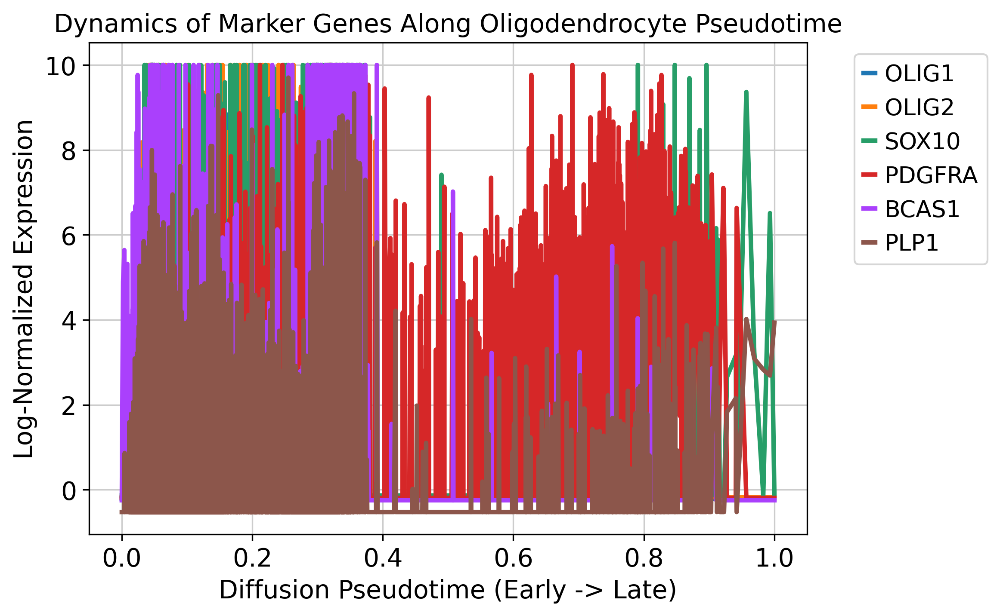

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# # Extract pseudotime and normalized expression data for the genes
# oligo_lineage_genes = ['OLIG1', 'OLIG2', 'SOX10', 'PDGFRA', 'BCAS1', 'PLP1']
# valid_genes = [g for g in oligo_lineage_genes if g in query_adata.var_names]

# # Create data frame of expressions from the normalized counts layer
# exp_matrix = query_adata[:, valid_genes].to_df(layer='norm_counts')
# exp_matrix['Pseudotime'] = query_adata.obs['dpt_pseudotime'].values

# # Melt the dataframe for easy plotting with seaborn
# melted_df = pd.melt(exp_matrix, id_vars=['Pseudotime'], var_name='Gene', value_name='Expression')

# # Generate the trend plot
# plt.figure(figsize=(8, 5))
# sns.lineplot(data=melted_df, x='Pseudotime', y='Expression', hue='Gene', linewidth=2.5)
# plt.title('Dynamics of Marker Genes Along Oligodendrocyte Pseudotime')
# plt.xlabel('Diffusion Pseudotime (Early -> Late)')
# plt.ylabel('Log-Normalized Expression')
# plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
# plt.tight_layout()
# plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/oligo_marker_trends_pseudotime.pdf', dpi=300)
# plt.show()

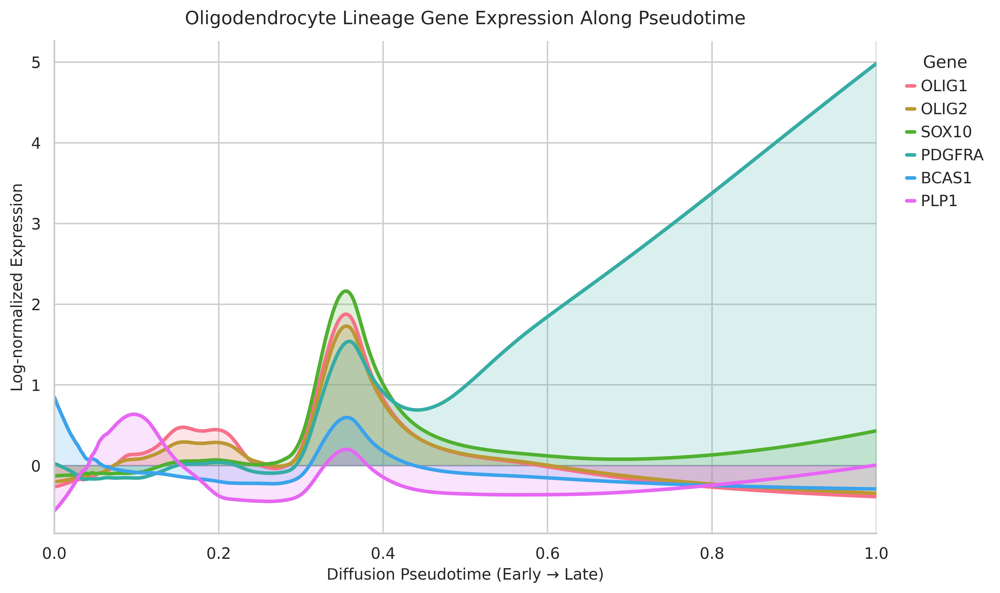

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:

# from statsmodels.nonparametric.smoothers_lowess import lowess

# # 1. Prepare expression data
# oligo_lineage_genes = ["OLIG1", "OLIG2", "SOX10", "PDGFRA", "BCAS1", "PLP1"]
# valid_genes = [g for g in oligo_lineage_genes if g in query_adata.var_names]
# if not valid_genes:
#     raise ValueError("None of the requested genes were found in query_adata.var_names.")
# exp_matrix = query_adata[:, valid_genes].to_df(layer="norm_counts")
# exp_matrix["Pseudotime"] = pd.to_numeric(query_adata.obs["dpt_pseudotime"], errors="coerce").to_numpy()
# exp_matrix = exp_matrix.replace([np.inf, -np.inf], np.nan).dropna(subset=["Pseudotime"])
# melted_df = exp_matrix.melt(id_vars="Pseudotime", var_name="Gene", value_name="Expression")
# melted_df = melted_df.sort_values("Pseudotime")

# # 2. Plot LOWESS-smoothed trends with transparent ribbons
# sns.set_theme(style="whitegrid")
# fig, ax = plt.subplots(figsize=(10, 6))
# palette = dict(zip(valid_genes, sns.color_palette("husl", n_colors=len(valid_genes))))
# for gene in valid_genes:
#     df = melted_df[melted_df["Gene"] == gene].dropna(subset=["Expression"]).sort_values("Pseudotime")
#     if len(df) < 10:
#         continue
#     smooth = lowess(df["Expression"], df["Pseudotime"], frac=0.18, it=0, return_sorted=True)
#     smooth_df = pd.DataFrame(smooth, columns=["Pseudotime", "SmoothedExpression"])
#     smooth_df = smooth_df.groupby("Pseudotime", as_index=False)["SmoothedExpression"].mean()
#     ax.plot(smooth_df["Pseudotime"], smooth_df["SmoothedExpression"], color=palette[gene], linewidth=2.5, label=gene)
#     ax.fill_between(smooth_df["Pseudotime"], smooth_df["SmoothedExpression"], alpha=0.18, color=palette[gene])
# ax.set_title("Oligodendrocyte Lineage Gene Expression Along Pseudotime", fontsize=13, pad=12)
# ax.set_xlabel("Diffusion Pseudotime (Early → Late)", fontsize=11)
# ax.set_ylabel("Log-normalized Expression", fontsize=11)
# ax.set_xlim(0, 1)
# ax.legend(title="Gene", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
# sns.despine()
# plt.tight_layout()
# # plt.savefig("smoothed.png", dpi=300, bbox_inches="tight")
# plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/oligo_marker_trends_smoothed.pdf', dpi=300, bbox_inches='tight')
# plt.show()

Selected cells: 3936
final_lineage_annotation
Oligodendrocyte Lineage    3834
OPC                          80
NC Derivatives               22
Name: count, dtype: Int64
computing PCA
    with n_comps=50
    finished (0:00:02)
computing neighbors
    finished (0:00:00)
computing UMAP
    finished (0:00:06)


<Figure size 1800x1500 with 0 Axes>

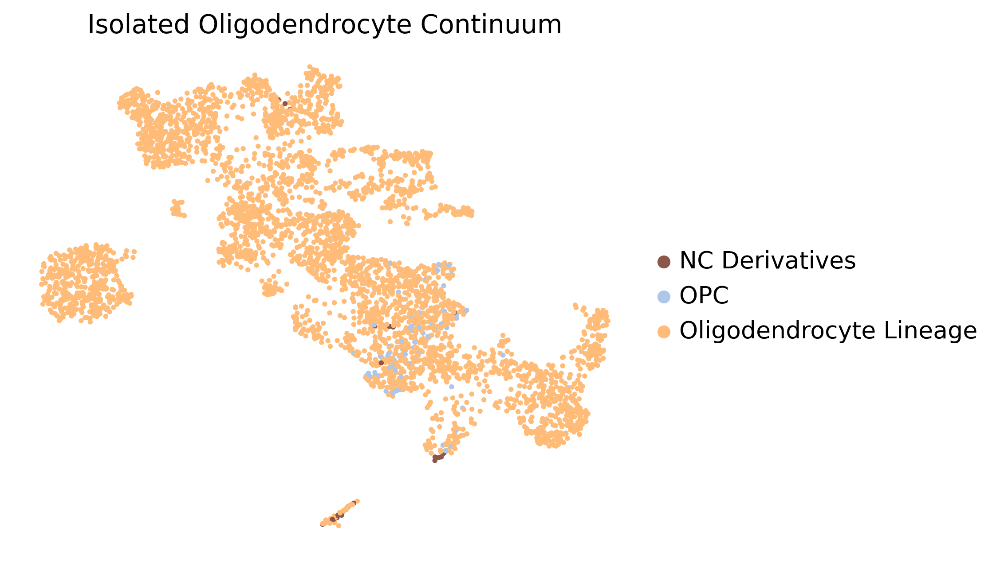

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# # 1. Filter AnnData to isolate only the target lineage continuum 
# # oligo_sub = query_adata[query_adata.obs['final_lineage_annotation'].isin(target_labels)].copy()
# target_labels = ["OPC", "NC Derivatives", "Oligodendrocyte Lineage"]
# lineage = query_adata.obs["final_lineage_annotation"].astype("string")
# mask = lineage.isin(target_labels).fillna(False).to_numpy(dtype=bool)
# print("Selected cells:", mask.sum())
# print(lineage[mask].value_counts())
# oligo_sub = query_adata[mask].copy()

# # 2. Re-run PCA and neighborhood construction locally on the subset to find fine structures
# oligo_sub.var["highly_variable"] = oligo_sub.var["highly_variable"].fillna(False).astype(bool)
# sc.tl.pca(oligo_sub, layer='norm_counts', mask_var='highly_variable')  # Use only highly variable genes for PCA
# # sc.tl.pca(oligo_sub, layer='norm_counts', mask_var=None)  # Use all genes for PCA
# sc.pp.neighbors(oligo_sub, use_rep='X_pca')  # Recompute native neighbors
# sc.tl.umap(oligo_sub)

# # 3. Plot the refined focused sub-trajectory UMAP
# plt.figure(figsize=(6, 5))
# sc.pl.umap(oligo_sub, color='final_lineage_annotation', title='Isolated Oligodendrocyte Continuum', show=False)
# # plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/isolated_oligo_trajectory_umap.pdf', bbox_inches='tight')
# plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/isolated_oligo_trajectory_umap_highlyVarGenes.pdf', bbox_inches='tight')

In [132]:
query_adata.obs.columns

Index(['sample', 'cell_line', 'genome', 'genotype', 'pair', 'sample_batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts',
       'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo',
       'log1p_total_counts_ribo', 'pct_counts_ribo', 'soupx_contamination', 'soupx_sample', 'doublet_method', 'doublet_score',
       'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden', 'snap_level_1', 'snap_level_2', 'snap_level_3', '_scvi_batch',
       '_scvi_labels', 'batch', 'annot_level_1', 'predicted_label', 'prediction_confidence', 'annot_level_2', 'annot_region_rev2',
       'annot_level_3_rev2', 'annot_ntt_rev2', 'annot_level_4_rev2', 'Oligo_Lineage_Score', 'final_lineage_annotation', 'dpt_pseudotime',
       'refined_oligo_annotation'],
      dtype='str')

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


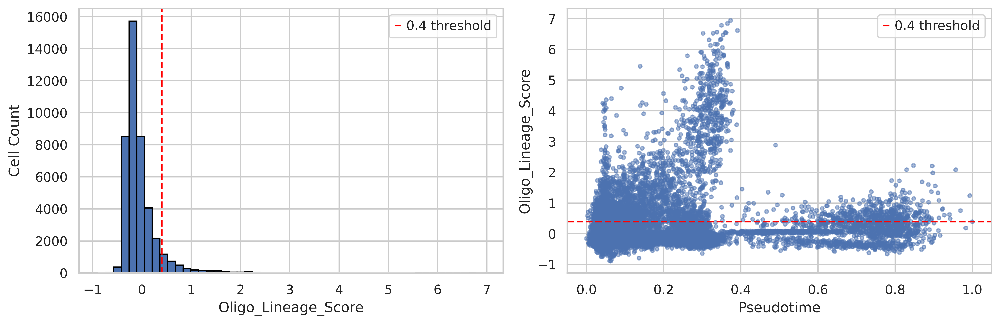

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# # Histogram
# axes[0].hist(query_adata.obs['Oligo_Lineage_Score'], bins=50, edgecolor='black')
# axes[0].axvline(0.4, color='red', linestyle='--', label='0.4 threshold')
# axes[0].set_xlabel('Oligo_Lineage_Score')
# axes[0].set_ylabel('Cell Count')
# axes[0].legend()

# # Score vs Pseudotime scatter
# axes[1].scatter(
#     query_adata.obs['dpt_pseudotime'], 
#     query_adata.obs['Oligo_Lineage_Score'],
#     alpha=0.5, s=10
# )
# axes[1].axhline(0.4, color='red', linestyle='--', label='0.4 threshold')
# axes[1].set_xlabel('Pseudotime')
# axes[1].set_ylabel('Oligo_Lineage_Score')
# axes[1].legend()

# plt.tight_layout()
# plt.show()

In [ ]:
# print(query_adata.obs['final_lineage_annotation'].value_counts())
# print(query_adata.obs['final_lineage_annotation'].unique())

final_lineage_annotation
Astrocyte                  12255
Neuron                     10391
MC                          6622
Glioblast                   5052
NPC                         4759
Oligodendrocyte Lineage     3834
CP                           541
OPC                           80
Neuroepithelium               40
NC Derivatives                22
EC                             2
Name: count, dtype: int64
['Neuron', 'MC', 'Astrocyte', 'Oligodendrocyte Lineage', 'NPC', ..., 'CP', 'OPC', 'Neuroepithelium', 'NC Derivatives', 'EC']
Length: 11
Categories (11, str): ['Astrocyte', 'CP', 'EC', 'Glioblast', ..., 'Neuroepithelium', 'Neuron', 'OPC', 'Oligodendrocyte Lineage']
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_late

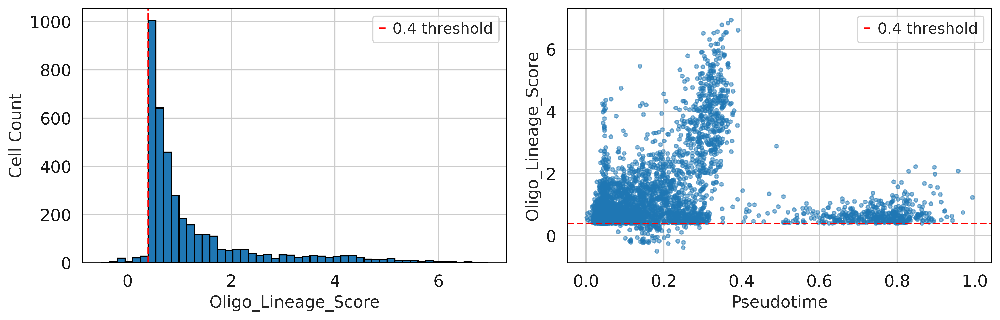

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# # Histogram
# axes[0].hist(query_adata.obs['Oligo_Lineage_Score'][(query_adata.obs['final_lineage_annotation'] == 'Oligodendrocyte Lineage') | (query_adata.obs['final_lineage_annotation'] == 'OPC')], bins=50, edgecolor='black')
# axes[0].axvline(0.4, color='red', linestyle='--', label='0.4 threshold')
# axes[0].set_xlabel('Oligo_Lineage_Score')
# axes[0].set_ylabel('Cell Count')
# axes[0].legend()

# # Score vs Pseudotime scatter
# axes[1].scatter(
#     query_adata.obs['dpt_pseudotime'][(query_adata.obs['final_lineage_annotation'] == 'Oligodendrocyte Lineage') | (query_adata.obs['final_lineage_annotation'] == 'OPC')], 
#     query_adata.obs['Oligo_Lineage_Score'][(query_adata.obs['final_lineage_annotation'] == 'Oligodendrocyte Lineage') | (query_adata.obs['final_lineage_annotation'] == 'OPC')],
#     alpha=0.5, s=10
# )
# axes[1].axhline(0.4, color='red', linestyle='--', label='0.4 threshold')
# axes[1].set_xlabel('Pseudotime')
# axes[1].set_ylabel('Oligo_Lineage_Score')
# axes[1].legend()

# plt.tight_layout()
# plt.show()

In [ ]:
# stages = {
#     'OPC (PT<0.4)': query_adata.obs['dpt_pseudotime'] < 0.4,
#     'Transitional (0.4<PT<0.65)': query_adata.obs['dpt_pseudotime'].between(0.4, 0.65),
#     'Mature (PT>0.65)': query_adata.obs['dpt_pseudotime'] > 0.65,
# }

# for gene in ['PDGFRA', 'OLIG2', 'BCAS1', 'PLP1']:
#     if gene in query_adata.var_names:
#         print(f"\n{gene} by stage:")
#         for stage_name, mask in stages.items():
#             expr = query_adata[mask, gene].layers['norm_counts'].toarray().flatten()
#             print(f"  {stage_name}: mean={expr.mean():.2f}, median={np.median(expr):.2f}")


PDGFRA by stage:
  OPC (PT<0.4): mean=-0.09, median=-0.19
  Transitional (0.4<PT<0.65): mean=0.87, median=-0.19
  Mature (PT>0.65): mean=3.25, median=3.45

OLIG2 by stage:
  OPC (PT<0.4): mean=0.00, median=-0.17
  Transitional (0.4<PT<0.65): mean=-0.16, median=-0.17
  Mature (PT>0.65): mean=-0.17, median=-0.17

BCAS1 by stage:
  OPC (PT<0.4): mean=0.00, median=-0.25
  Transitional (0.4<PT<0.65): mean=-0.23, median=-0.25
  Mature (PT>0.65): mean=-0.22, median=-0.25

PLP1 by stage:
  OPC (PT<0.4): mean=0.01, median=-0.53
  Transitional (0.4<PT<0.65): mean=-0.46, median=-0.53
  Mature (PT>0.65): mean=-0.28, median=-0.53
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: g

In [ ]:
# # Go back to raw counts - check BEFORE any normalization
# if 'counts' in query_adata.layers:
#     raw_counts = query_adata.layers['counts'].toarray()
# elif hasattr(query_adata, 'raw'):
#     raw_counts = query_adata.raw.X.toarray()
# else:
#     raw_counts = query_adata.X.toarray()  # Hope this is counts

# for gene in ['OLIG1', 'OLIG2', 'SOX10', 'PDGFRA', 'BCAS1', 'PLP1']:
#     if gene in query_adata.var_names:
#         idx = query_adata.var_names.get_loc(gene)
#         expr = raw_counts[:, idx]
#         n_expr = (expr > 0).sum()
#         print(f"{gene}:")
#         print(f"  Cells expressing: {n_expr:,} / {len(expr):,} ({100*n_expr/len(expr):.1f}%)")
#         print(f"  Mean counts (all): {expr.mean():.2f}")
#         print(f"  Mean counts (>0): {expr[expr > 0].mean():.2f}")
#         print(f"  Max count: {expr.max():.0f}")

OLIG1:
  Cells expressing: 2,628 / 43,598 (6.0%)
  Mean counts (all): 0.24
  Mean counts (>0): 4.03
  Max count: 50
OLIG2:
  Cells expressing: 1,716 / 43,598 (3.9%)
  Mean counts (all): 0.07
  Mean counts (>0): 1.88
  Max count: 15
SOX10:
  Cells expressing: 1,053 / 43,598 (2.4%)
  Mean counts (all): 0.05
  Mean counts (>0): 2.07
  Max count: 16
PDGFRA:
  Cells expressing: 2,023 / 43,598 (4.6%)
  Mean counts (all): 0.17
  Mean counts (>0): 3.61
  Max count: 37
BCAS1:
  Cells expressing: 4,374 / 43,598 (10.0%)
  Mean counts (all): 0.23
  Mean counts (>0): 2.29
  Max count: 151
PLP1:
  Cells expressing: 12,588 / 43,598 (28.9%)
  Mean counts (all): 0.82
  Mean counts (>0): 2.85
  Max count: 127
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown,

[<Axes: title={'center': 'OLIG2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'PDGFRA'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'PLP1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'BCAS1'}, xlabel='UMAP1', ylabel='UMAP2'>]

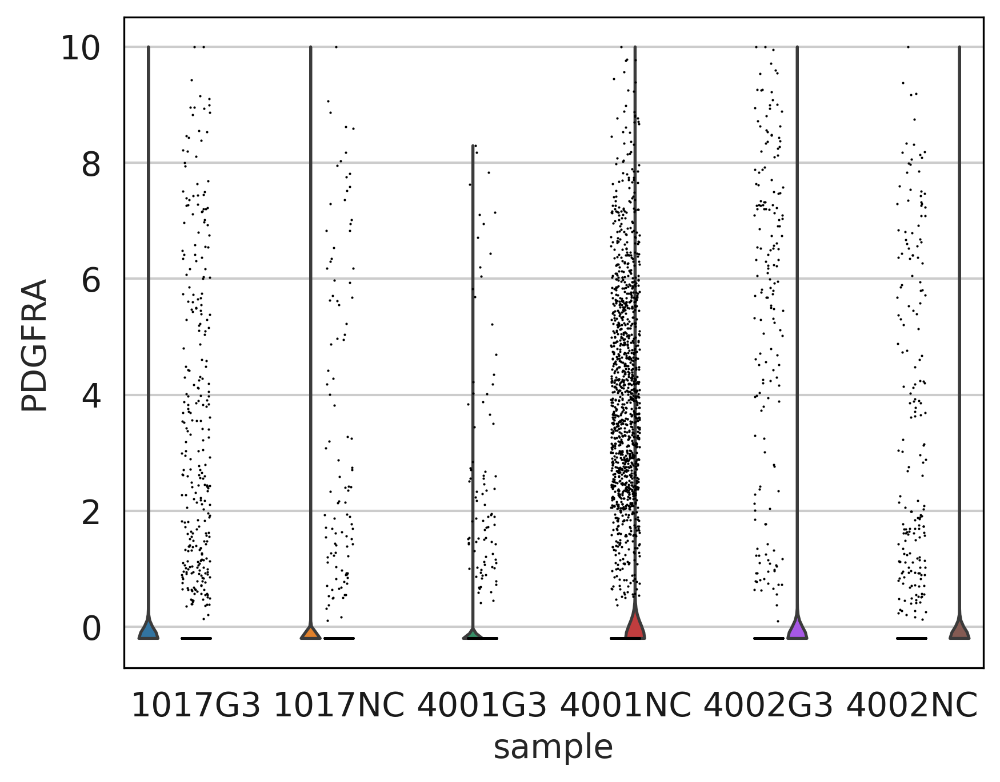

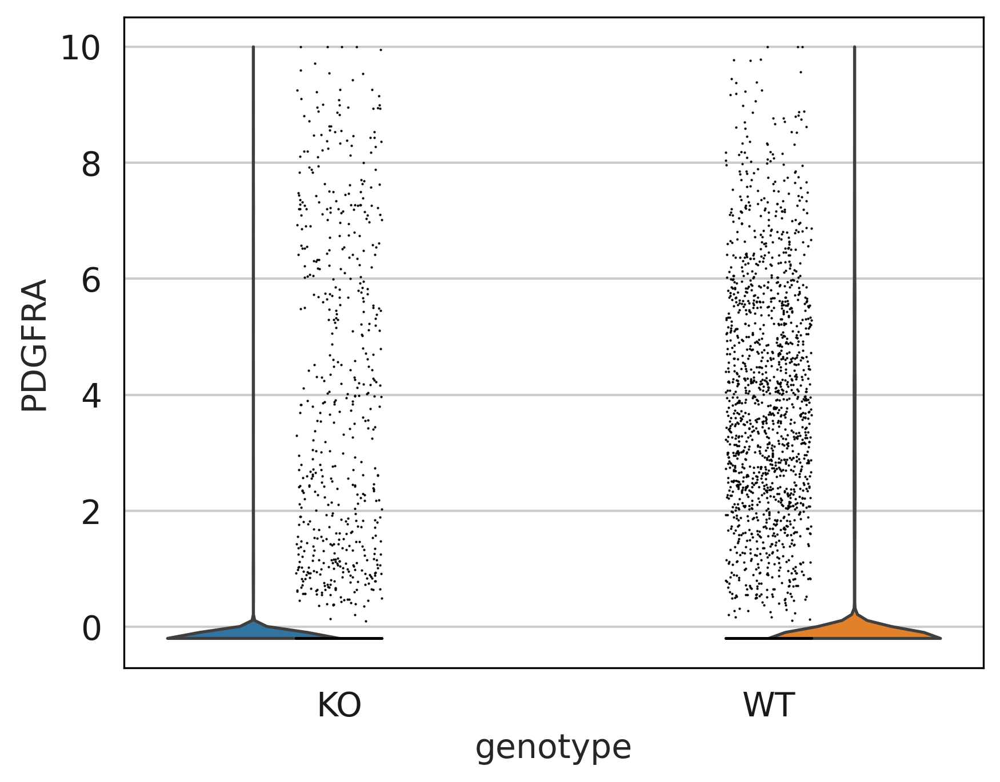

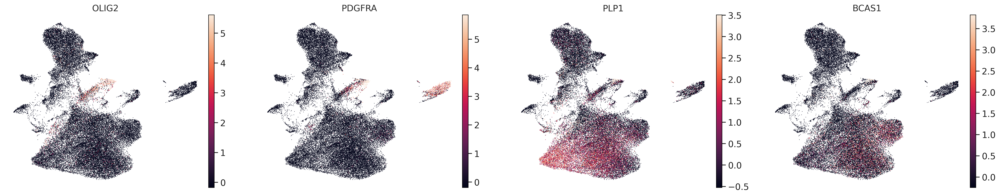

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# # Maybe organoids are just too young
# # Plot PDGFRA by known developmental/sample metadata

# if 'sample' in query_adata.obs.columns:
#     sc.pl.violin(query_adata, 'PDGFRA', groupby='sample', layer='norm_counts', show=False)
    
# if 'genotype' in query_adata.obs.columns:
#     sc.pl.violin(query_adata, 'PDGFRA', groupby='genotype', layer='norm_counts', show=False)

# # Plot all markers to see sparsity patterns
# sc.pl.umap(query_adata, color=['OLIG2', 'PDGFRA', 'PLP1', 'BCAS1'], 
#            layer='norm_counts', show=False, vmin='p1', vmax='p99')

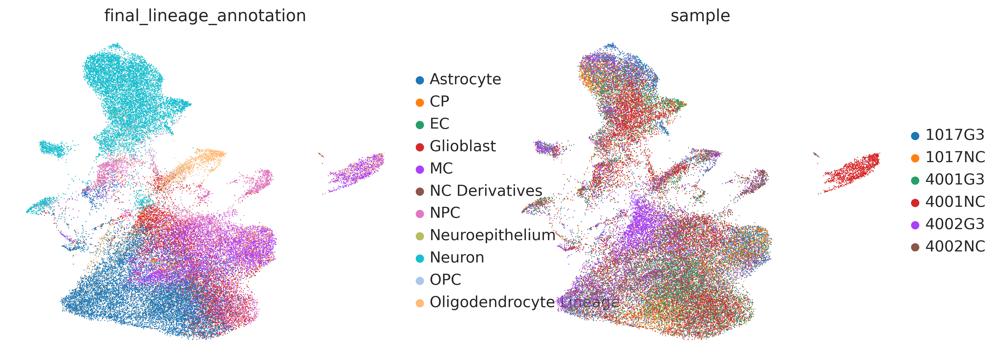

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# # # Accept HNOCA's OPC vs Oligodendrocyte Lineage designation
# # # This is reference-based and more reliable than your marker-poor data
# # query_adata.obs['oligo_annotation_final'] = query_adata.obs['final_lineage_annotation']

# # print(query_adata.obs['oligo_annotation_final'].value_counts())

# # Optionally stratify by SAMPLE (it explains PDGFRA variation better than pseudotime)
# sc.pl.umap(query_adata, color=['final_lineage_annotation', 'sample'], layer='norm_counts')

oligo_sample_annotation
Astrocyte (4001G3)         2737
Neuron (1017G3)            2572
Astrocyte (1017NC)         2333
Neuron (4001NC)            2293
Astrocyte (4001NC)         2213
                           ... 
NC Derivatives (1017G3)       2
NC Derivatives (1017NC)       2
EC (4001NC)                   1
NC Derivatives (4001NC)       1
EC (4002NC)                   1
Name: count, Length: 61, dtype: int64


/users/ahanuman/.conda/envs/hnoca_gpu/lib/python3.12/site-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


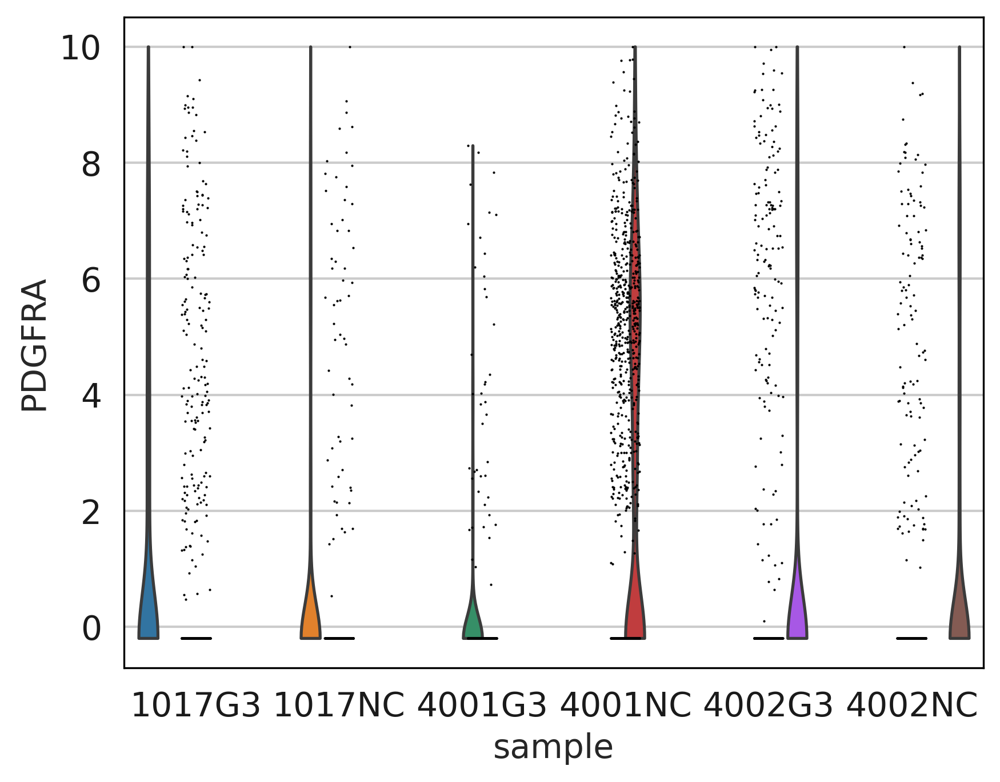

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# # Annotate with both HNOCA classification AND sample
# query_adata.obs['oligo_sample_annotation'] = (
#     query_adata.obs['final_lineage_annotation'].astype(str) + ' (' + 
#     query_adata.obs['sample'].astype(str) + ')'
# )

# # Now you can see: which samples have robust oligo signatures?
# print(query_adata.obs['oligo_sample_annotation'].value_counts())

# # Plot PDGFRA by sample + annotation
# sc.pl.violin(query_adata[query_adata.obs['final_lineage_annotation'].isin(['OPC', 'Oligodendrocyte Lineage'])],
#              'PDGFRA', groupby='sample', layer='norm_counts')

In [ ]:
# # Rank genes by correlation with pseudotime
# from scipy.stats import spearmanr

# pt = query_adata.obs['dpt_pseudotime'].values

# for gene in ['OLIG1', 'OLIG2', 'SOX10', 'PDGFRA', 'BCAS1', 'PLP1']:
#     if gene in query_adata.var_names:
#         expr = query_adata[:, gene].layers['norm_counts'].toarray().flatten()
#         corr, pval = spearmanr(pt, expr)
#         print(f"{gene}: rho={corr:.3f}, p={pval:.2e}")

OLIG1: rho=0.117, p=5.56e-133
OLIG2: rho=0.101, p=9.44e-100
SOX10: rho=0.121, p=1.10e-142
PDGFRA: rho=0.198, p=0.00e+00
BCAS1: rho=-0.221, p=0.00e+00
PLP1: rho=-0.141, p=9.32e-193
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# # Define population based on pseudotime + marker confirmation
# query_adata.obs['refined_oligo_annotation'] = query_adata.obs['annot_level_1'].astype(str)

# # OPCs: Early/transitional (pseudotime < 0.5 + high PDGFRA/SOX10)
# is_opc = (query_adata.obs['dpt_pseudotime'] < 0.5) & (query_adata.obs['Oligo_Lineage_Score'] > 0.2)
# query_adata.obs.loc[is_opc, 'refined_oligo_annotation'] = 'OPC'

# # Mature OLs: Late pseudotime (pseudotime > 0.6 + high PDGFRA/BCAS1/PLP1)
# is_mature_ol = (query_adata.obs['dpt_pseudotime'] > 0.6) & (query_adata.obs['Oligo_Lineage_Score'] > 0.3)
# query_adata.obs.loc[is_mature_ol, 'refined_oligo_annotation'] = 'Mature Oligodendrocyte'

# # Transitional: Middle range
# is_transitional = (query_adata.obs['dpt_pseudotime'].between(0.4, 0.65)) & (query_adata.obs['Oligo_Lineage_Score'] > 0.2)
# query_adata.obs.loc[is_transitional, 'refined_oligo_annotation'] = 'OL Precursor (Transitional)'

# OL_UMAP_PDF = "/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/refined_oligo_annotation_UMAP.pdf"

# # 2. Render and save the static cluster UMAP
# sc.settings.set_figure_params(figsize=(6, 5), dpi=300, frameon=False)
# ax = sc.pl.umap(query_adata, color='refined_oligo_annotation', show=False)
# ax.set_title("Organoid Profiles with Refined Oligodendrocyte Annotation")
# ax.figure.savefig(OL_UMAP_PDF, bbox_inches='tight')

In [ ]:
# for threshold in [0.2, 0.3, 0.4, 0.5]:
#     n_oligo = (query_adata.obs['Oligo_Lineage_Score'] > threshold).sum()
#     print(f"Threshold {threshold}: {n_oligo} cells ({100*n_oligo/len(query_adata):.1f}%)")

In [ ]:
# print(oligo_sub.var["highly_variable"].dtype)
# print(oligo_sub.var["highly_variable"].value_counts(dropna=False))

In [ ]:
# query_adata[query_adata.obs['final_lineage_annotation'].isin(target_labels)]
# query_adata.obs['final_lineage_annotation'].value_counts()
# query_adata


In [ ]:
# import pandas as pd
# genes = ["OLIG1", "OLIG2", "SOX10", "PDGFRA", "BCAS1", "PLP1"]

# query_adata.obs["dpt_pseudotime"].hist(bins=100)        # where do cells actually sit?
# print(query_adata.X.min())                              # negative => scaled, not log-normalized

# df = sc.get.obs_df(query_adata, keys=["dpt_pseudotime"] + genes, layer="norm_counts")
# df["bin"] = pd.cut(df["dpt_pseudotime"], 30)
# print(df.groupby("bin", observed=True).size())    # cells per bin; thin bins mean unreliable curves
# df.groupby("bin", observed=True)[genes].mean().plot()

In [ ]:
# oligo_lineage_genes = ['OLIG1', 'OLIG2', 'SOX10', 'PDGFRA', 'BCAS1', 'PLP1']
# valid_genes = [g for g in oligo_lineage_genes if g in query_adata.var_names]

# # a) confirm the layer is scaled
# sub = query_adata[:, valid_genes].layers["norm_counts"]
# sub = sub.toarray() if hasattr(sub, "toarray") else np.asarray(sub)
# print(sub.min(), sub.max())          # max == 10.0 confirms scale(max_value=10)

# # b) proper log-normalization from raw counts on ALL genes (not the 3000 subset)
# tmp = query_adata[query_adata.obs_names].copy()    # assumes query_full still has layers["counts"]
# tmp.X = tmp.layers["counts"].copy()
# sc.pp.normalize_total(tmp, target_sum=1e4)
# sc.pp.log1p(tmp)
# ln = tmp[:, valid_genes].to_df()

# # c) identify the island
# late = query_adata.obs["dpt_pseudotime"] > 0.4
# tmp.obs["grp"] = (query_adata.obs["final_lineage_annotation"].astype(str)
#                   + np.where(late, " (pt>0.4)", "")).loc[tmp.obs_names].values
# dot_plot_genes = [g for g in ["PDGFRA", "PDGFRB", "COL1A1", "DCN", "LUM", "OLIG2", "SOX10", "GFAP", "PLP1"] if g in tmp.var_names]
# sc.pl.dotplot(tmp, dot_plot_genes, groupby="grp")

In [ ]:
# mask = (query_adata.obs["final_lineage_annotation"].isin(["OPC", "Oligodendrocyte Lineage"])
#         & (query_adata.obs["Oligo_Lineage_Score"] > 1.5))     # choose from the histogram; also drop island cells
# ol = query_adata[mask].copy()

# sc.pp.neighbors(ol, use_rep="X_scANVI")                       # your latent key
# sc.tl.diffmap(ol)
# root = int(np.argmax(ln.loc[ol.obs_names, ["PDGFRA", "OLIG2"]].sum(1).values))   # OPC-like root
# ol.uns["iroot"] = root
# sc.tl.dpt(ol)

# df = ln.loc[ol.obs_names].copy()
# df["bin"] = pd.cut(ol.obs["dpt_pseudotime"].values, np.linspace(0, 1, 21))
# g = df.groupby("bin", observed=True)
# m = g[valid_genes].mean()[g.size() >= 30]                     # drop thin bins
# m.index = [iv.mid for iv in m.index]
# m.plot(figsize=(8, 4), ylabel="Mean log-normalized expression", xlabel="Pseudotime")

In [ ]:
# # A. Proper log-normalization on ALL genes
# full = query_adata[query_adata.obs_names].copy()
# full.X = full.layers["counts"].copy()
# sc.pp.normalize_total(full, target_sum=1e4)
# sc.pp.log1p(full)

# markers = ["OLIG1","OLIG2","SOX10","PDGFRA","CSPG4","BCAS1","GPR17","MBP","MOG","MAG","MOBP","CNP","PLP1","COL1A1","DCN","GFAP"]
# present = [g for g in markers if g in full.var_names]
# print("absent:", sorted(set(markers) - set(present)))
# print((sc.get.obs_df(full, present) > 0).mean().round(3))     # fraction of cells expressing each

# # B. Stage-specific scores on the right data (gene lists are from memory, so check them)
# sets = {"OPC": ["PDGFRA","CSPG4","PCDH15","LHFPL3"],
#         "COP_NFOL": ["BCAS1","GPR17","ENPP6","TCF7L2","NKX2-2"],
#         "MOL": ["MBP","MOG","MAG","MOBP","CNP","CLDN11"]}
# for k, g in sets.items():
#     sc.tl.score_genes(full, [x for x in g if x in full.var_names], score_name=f"score_{k}")

# # C. Candidate lineage by co-expression, excluding mesenchymal cells (first pass; tune the cutoffs)
# e = sc.get.obs_df(full, ["OLIG1","OLIG2","SOX10","COL1A1","DCN","LUM"])
# full.obs["oligo_candidate"] = ((e.OLIG1 > 0) | (e.OLIG2 > 0)) & (e.SOX10 > 0) & (e[["COL1A1","DCN","LUM"]].max(axis=1) < 1)
# print(full.obs.groupby("sample")["oligo_candidate"].agg(["sum", "mean"]))

# # D. Cluster the candidates and annotate clusters instead of thresholding single cells
# sub = full[full.obs["oligo_candidate"]].copy()
# sub.obsm["X_latent"] = query_adata[sub.obs_names].obsm["X_scANVI"]    # use your latent key
# sc.pp.neighbors(sub, use_rep="X_latent")
# sc.tl.leiden(sub, resolution=0.6)
# sc.pl.dotplot(sub, present, groupby="leiden", standard_scale="var")

In [ ]:
# query_adata.var.shape
# ref_adata.var.shape

# markers = ["OLIG1","OLIG2","SOX10","PDGFRA","CSPG4","BCAS1","GPR17","MBP","MOG","MAG","MOBP","CNP","PLP1","COL1A1","DCN","GFAP"]
# present = [g for g in markers if g in ref_adata.var_names]
# print("absent:", sorted(set(markers) - set(present)))

absent: ['CNP', 'CSPG4', 'MBP', 'MOBP', 'MOG']
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
query_adata.obs.groupby("sample")["total_counts"].sum()
sample_summary = query_adata.obs.groupby("sample")["total_counts"].agg(
    cell_count="count", total_sum="sum"
)
print(sample_summary)

print(query_adata.layers['counts'].shape)


        cell_count    total_sum
sample                         
1017G3        6732  119087528.0
1017NC        6834  101217320.0
4001G3        8633  108774920.0
4001NC        9982  108347952.0
4002G3        6193   88235112.0
4002NC        5224  112401968.0
(43598, 3000)
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!

--- Proportion Differences: annot_level_1 ---
                 baseline_props  mean_props_KO  mean_props_WT  prop_ratio  t_statistics  p_values  adjusted_p_values
clusters                                                                                                            
Astrocyte              0.307078       0.316534       0.307832    1.028270      0.145067  0.889472           0.891618
CP                     0.012707       0.016939       0.009689    1.748324      0.891085  0.407652           0.891618
EC                     0.000092       0.000000       0.000225    0.000000     -2.321207  0.059947           0.599467
Glioblast              0.127529       0.139557       0.117607    1.186638      0.142228  0.891618           0.891618
MC                     0.167187       0.146104       0.175988    0.830196     -0.645817  0.542614           0.891618
NC Derivatives         0.001651       0.000408       0.003729 

/users/ahanuman/.local/lib/python3.12/site-packages/scanpro/scanpro.py:347: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  out.results[col].fillna(0, inplace=True)
/users/ahanuman/.local/lib/python3.12/site-packages/scanpro/scanpro.py:349: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained 

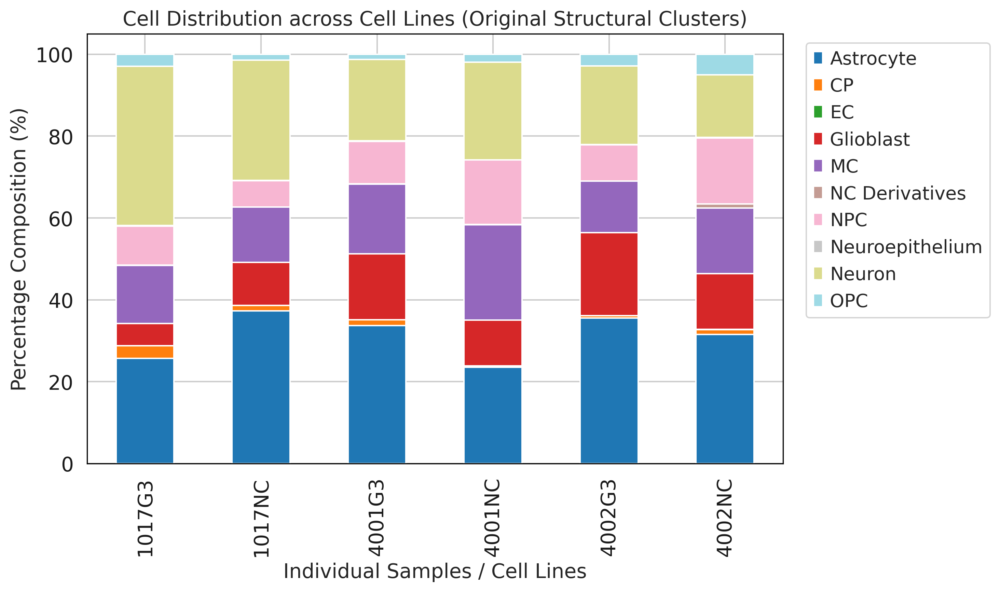

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# from scanpro import scanpro

# 1. Calculate statistical shifts on structural annotations
out_annot = scanpro(
    query_adata, 
    clusters_col='annot_level_1', 
    conds_col='genotype', 
    samples_col='sample'
)

print("\n--- Proportion Differences: annot_level_1 ---")
print(out_annot.results)

# 2. Generate Stacked Bar Plot for original labels
props_annot = pd.crosstab(query_adata.obs['sample'], query_adata.obs['annot_level_1'], normalize='index') * 100

ax2 = props_annot.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.title('Cell Distribution across Cell Lines (Original Structural Clusters)')
plt.xlabel('Individual Samples / Cell Lines')
plt.ylabel('Percentage Composition (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/scanpro_proportions_annot_level_1.pdf', bbox_inches='tight')
plt.show()


In [ ]:
# from scanpro import scanpro

# 1. Calculate proportions and differential statistics via scanpro
out_final = scanpro(
    query_adata, 
    clusters_col='annot_level_2', 
    conds_col='genotype', 
    samples_col='sample'
)

# 2. Display the statistical results summary
print("--- Proportion Differences: annot_level_2 ---")
print(out_final.results)

# 3. Generate Stacked Bar Plot via Pandas/Matplotlib
# Grouping counts systematically by sample to compute independent relative percentages
props_final = pd.crosstab(query_adata.obs['sample'], query_adata.obs['annot_level_2'], normalize='index') * 100

ax = props_final.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set3')
plt.title('Cell Distribution across Cell Lines (Final Lineage Labels)')
plt.xlabel('Individual Samples / Cell Lines')
plt.ylabel('Percentage Composition (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/scanpro_proportions_annot_level_2.pdf', bbox_inches='tight')
plt.show()

In [ ]:
# from scanpro import scanpro

# 1. Calculate statistical shifts on structural annotations
out_annot = scanpro(
    query_adata, 
    clusters_col='snap_level_1', 
    conds_col='genotype', 
    samples_col='sample'
)

print("\n--- Proportion Differences: snap_level_1 ---")
print(out_annot.results)

# 2. Generate Stacked Bar Plot for original labels
props_annot = pd.crosstab(query_adata.obs['sample'], query_adata.obs['snap_level_1'], normalize='index') * 100

ax2 = props_annot.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.title('Cell Distribution across Cell Lines (Original Structural Clusters)')
plt.xlabel('Individual Samples / Cell Lines')
plt.ylabel('Percentage Composition (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/scanpro_proportions_snap_level_1.pdf', bbox_inches='tight')
plt.show()


In [ ]:
# 1. Calculate statistical shifts on structural annotations
out_annot = scanpro(
    query_adata, 
    clusters_col='snap_level_2', 
    conds_col='genotype', 
    samples_col='sample'
)

print("\n--- Proportion Differences: snap_level_2 ---")
print(out_annot.results)

# 2. Generate Stacked Bar Plot for original labels
props_annot = pd.crosstab(query_adata.obs['sample'], query_adata.obs['snap_level_2'], normalize='index') * 100

ax2 = props_annot.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.title('Cell Distribution across Cell Lines (Original Structural Clusters)')
plt.xlabel('Individual Samples / Cell Lines')
plt.ylabel('Percentage Composition (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_fai/3_analysis/02_cell_annotations/scanpro_proportions_snap_level_2.pdf', bbox_inches='tight')
plt.show()


#### Reproducibility information

In [71]:
from prettytable import PrettyTable
from print_versions import print_versions
from platform import python_version, uname

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [72]:
# Create a PrettyTable object for the system information
sys_info_table = PrettyTable()
sys_info_table.field_names = ["Attribute", "Value"]

# Add system information to the table
sys_info_table.add_row(["Python Version", python_version()])
uname_info = uname()
sys_info_table.add_row(["System", uname_info.system])
sys_info_table.add_row(["Node Name", uname_info.node])
sys_info_table.add_row(["Release", uname_info.release])
sys_info_table.add_row(["Version", uname_info.version])
sys_info_table.add_row(["Machine", uname_info.machine])
sys_info_table.add_row(["Processor", uname_info.processor])

# Print the system information table
print("System Information:")
print(sys_info_table)

System Information:
+----------------+----------------------------------------------------+
|   Attribute    |                       Value                        |
+----------------+----------------------------------------------------+
| Python Version |                      3.12.14                       |
|     System     |                       Linux                        |
|   Node Name    |               compute-117.cm.cluster               |
|    Release     |            5.14.0-427.13.1.el9_4.x86_64            |
|    Version     | #1 SMP PREEMPT_DYNAMIC Wed May 1 19:11:28 UTC 2024 |
|    Machine     |                       x86_64                       |
|   Processor    |                       x86_64                       |
+----------------+----------------------------------------------------+
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: 

In [73]:
print_versions(globals())

/users/ahanuman/.conda/envs/hnoca_gpu/lib/python3.12/site-packages/print_versions/versions.py:10: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if getattr(m, "__version__", None):
/users/ahanuman/.conda/envs/hnoca_gpu/lib/python3.12/site-packages/print_versions/versions.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  versions[m.__name__] = m.__version__
/users/ahanuman/.conda/envs/hnoca_gpu/lib/python3.12/site-packages/print_versions/versions.py:10: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if getattr(m, "__version__", None):
/users/ahanuman/.conda/envs/hnoca_gpu/lib/python3.12/site-packages/print_versions/versions.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  versions[m.__name__] = m.__version__


pandas==3.0.1
anndata==0.13.3.post0
numpy==2.5.3
scanpy==1.12.4
scvi==1.5.1
torch==2.6.0+cu124
matplotlib==3.10.8
flax==0.12.9
hnoca==0.2.2.dev5+g19a8b06ce
prettytable==3.18.0
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
